# Clustering traffic accidents with injuries – Germany 2025 (Unfallatlas)

**Goal:** Cluster all accidents with injuries into **3 clusters** with three algorithms and check whether the clusters match the actual
accident category `UKATEGORIE` (1 = killed, 2 = seriously injured, 3 = slightly injured).

Algorithms: **K-Means**, **Gaussian Mixture (GMM)**, **Agglomerative (Ward)**.

**Accuracy:** Clustering gives no label names, only cluster numbers 0/1/2. Each cluster is therefore matched one-to-one to a category
so that the most accidents are correct (Hungarian algorithm). Then accuracy = share of accidents whose cluster matches their category.

<a class="anchor" id="0.1"></a>

# Table of Contents

1. [Part 1: Three clustering algorithms vs. actual accident category](#part1)
   - 1 [Load data](#1)
   - 2 [Features](#2)
   - 3 [Helper: map clusters to categories and compute accuracy](#3)
   - 4 [K-Means (all accidents)](#4)
   - 5 [Gaussian Mixture (all accidents)](#5)
   - 6 [Agglomerative clustering (random sample of 10,000 accidents)](#6)
   - 7 [Comparison](#7)
   - 8 [Conclusion](#8)
2. [Part 2: Dealing with the class imbalance (focus: *killed*)](#part2)
   - 9 [Part 1 results with imbalance-aware metrics](#9)
   - 10 [Balanced training sample + held-out test set](#10)
     - [Effect of the time features](#10.1)
   - 11 [Conclusion on the imbalance](#11)
3. [Part 3: DBSCAN with grid search (exactly 3 clusters)](#part3)
   - 12 [Conclusion on DBSCAN](#12)
4. [Part 4: SMOTE oversampling instead of undersampling](#part4)
   - 13 [K-Means, Gaussian Mixture, Agglomerative and DBSCAN on the SMOTE data](#13)
   - 14 [Undersampling vs. SMOTE (same test set)](#14)
   - 15 [Conclusion on SMOTE](#15)

# Part 1: Three clustering algorithms vs. actual accident category <a class="anchor" id="part1"></a>

## 1. Load data <a class="anchor" id="1"></a>

[Table of Contents](#0.1)

In [1]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import accuracy_score, adjusted_rand_score
from scipy.optimize import linear_sum_assignment
pd.set_option('display.max_columns', 30)

df = pd.read_csv('data/Unfallorte_2025_LR_BasisDLM.csv', sep=';', decimal=',', dtype={'UIDENTSTLAE': str})
print(df.shape)
df['UKATEGORIE'].value_counts().sort_index()

(273007, 25)


UKATEGORIE
1      2477
2     40430
3    230100
Name: count, dtype: int64

## 2. Features <a class="anchor" id="2"></a>

[Table of Contents](#0.1)

* **Accident attributes:** kind (`UART`), type (`UTYP1`), light, road condition and the involved road users.
  Categorical columns are one-hot encoded (0/1).
* **Time (proxy for traffic density):** hour (`USTUNDE`), month (`UMONAT`) and weekday (`UWOCHENTAG`).
  They are cyclic (23:00 is next to 0:00, December next to January), so each is encoded as a **sine/cosine pair**.
  This keeps them in the range -1…1, similar to the 0/1 columns, and adds only 6 columns.
* Location, IDs and coordinates are not used. The label `UKATEGORIE` is **not** used for clustering.

In [2]:
cat_cols = ['UART', 'UTYP1', 'ULICHTVERH', 'IstStrassenzustand']
bin_cols = ['IstRad', 'IstPKW', 'IstFuss', 'IstKrad', 'IstGkfz', 'IstSonstige']

# raw table: categorical columns + time columns as sine/cosine pairs (cyclic)
raw = df[cat_cols + bin_cols].copy()
time_cols = {'USTUNDE': 24, 'UMONAT': 12, 'UWOCHENTAG': 7}
for col, period in time_cols.items():
    raw[col + '_sin'] = np.sin(2 * np.pi * df[col] / period)
    raw[col + '_cos'] = np.cos(2 * np.pi * df[col] / period)
n_time = 2 * len(time_cols)   # the last 6 columns are the time features

def encode(r):
    """One-hot encode the categorical columns; keep the 0/1 flags and the time columns."""
    return pd.get_dummies(r[cat_cols].astype(str)).join(r[bin_cols]).astype(float).join(r.iloc[:, -n_time:])

features = encode(raw)
X = features.values
y = df['UKATEGORIE'].values
print(X.shape)

(273007, 35)


Share of *killed* accidents by hour – fatal accidents are 2–3× more frequent at night (low traffic density):

In [3]:
(df.groupby('USTUNDE')['UKATEGORIE'].apply(lambda s: (s == 1).mean() * 100).round(2)
   .to_frame('killed %').T)

USTUNDE,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
killed %,1.75,1.91,2.27,2.72,2.37,1.0,0.94,0.57,0.73,0.96,0.98,0.99,0.87,0.83,0.9,0.85,0.77,0.89,0.71,0.8,1.07,0.96,1.2,1.57


## 3. Helper: map clusters to categories and compute accuracy <a class="anchor" id="3"></a>

[Table of Contents](#0.1)

In [4]:
labels = {1: 'killed', 2: 'seriously injured', 3: 'slightly injured'}

def evaluate(y_true, clusters):
    # confusion table: rows = actual category, columns = cluster
    ct = pd.crosstab(y_true, clusters).reindex(index=[1, 2, 3], columns=[0, 1, 2], fill_value=0)
    rows, cols = linear_sum_assignment(-ct.values)          # best one-to-one cluster -> category
    mapping = {ct.columns[c]: ct.index[r] for r, c in zip(rows, cols)}
    y_pred = pd.Series(clusters).map(mapping).values
    acc = accuracy_score(y_true, y_pred)
    # chance reference: same cluster sizes, randomly shuffled
    rng = np.random.default_rng(0)
    shuffled = rng.permutation(clusters)
    ct_s = pd.crosstab(y_true, shuffled).reindex(index=[1, 2, 3], columns=[0, 1, 2], fill_value=0)
    r_s, c_s = linear_sum_assignment(-ct_s.values)
    chance = ct_s.values[r_s, c_s].sum() / len(y_true)
    ct.index = [labels[i] for i in ct.index]
    ct.columns = [f'cluster {c} -> {labels[mapping[c]]}' for c in ct.columns]
    return acc, chance, adjusted_rand_score(y_true, clusters), ct, y_pred

results = {}
preds = {}   # mapped predictions, reused in section 9

## 4. K-Means (all accidents) <a class="anchor" id="4"></a>

[Table of Contents](#0.1)

In [5]:
km = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X)
acc, chance, ari, ct, preds['K-Means'] = evaluate(y, km)
results['K-Means'] = (len(y), acc, chance, ari)
print(f'Accuracy: {acc:.3f}   (random clusters: {chance:.3f})   ARI: {ari:.4f}')
ct

Accuracy: 0.392   (random clusters: 0.399)   ARI: 0.0021


,cluster 0 -> slightly injured,cluster 1 -> seriously injured,cluster 2 -> killed
killed,961,796,720
seriously injured,17248,13498,9684
slightly injured,92878,86631,50591


## 5. Gaussian Mixture (all accidents) <a class="anchor" id="5"></a>

[Table of Contents](#0.1)

In [6]:
gmm = GaussianMixture(n_components=3, random_state=42).fit_predict(X)
acc, chance, ari, ct, preds['Gaussian Mixture'] = evaluate(y, gmm)
results['Gaussian Mixture'] = (len(y), acc, chance, ari)
print(f'Accuracy: {acc:.3f}   (random clusters: {chance:.3f})   ARI: {ari:.4f}')
ct

Accuracy: 0.434   (random clusters: 0.432)   ARI: 0.0023


,cluster 0 -> killed,cluster 1 -> seriously injured,cluster 2 -> slightly injured
killed,742,712,1023
seriously injured,10167,12107,18156
slightly injured,53609,70925,105566


## 6. Agglomerative clustering (random sample of 10,000 accidents) <a class="anchor" id="6"></a>

[Table of Contents](#0.1)

Agglomerative clustering needs memory that grows with n², so 273k rows are not feasible. A random sample of 10,000 is used.

In [7]:
idx = np.random.default_rng(42).choice(len(X), size=10_000, replace=False)
agg = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(X[idx])
acc, chance, ari, ct, preds['Agglomerative (sample)'] = evaluate(y[idx], agg)
results['Agglomerative (sample)'] = (len(idx), acc, chance, ari)
print(f'Accuracy: {acc:.3f}   (random clusters: {chance:.3f})   ARI: {ari:.4f}')
ct

Accuracy: 0.511   (random clusters: 0.513)   ARI: 0.0005


,cluster 0 -> slightly injured,cluster 1 -> seriously injured,cluster 2 -> killed
killed,60,14,21
seriously injured,817,319,312
slightly injured,4775,1548,2134


## 7. Comparison <a class="anchor" id="7"></a>

[Table of Contents](#0.1)

In [8]:
summary = pd.DataFrame(results, index=['n accidents', 'Accuracy', 'Accuracy random clusters', 'ARI']).T
summary.loc['Baseline: always "slightly injured"'] = [len(y), (y == 3).mean(), np.nan, 0.0]
summary.round(3)

,n accidents,Accuracy,Accuracy random clusters,ARI
K-Means,273007.0,0.392,0.399,0.002
Gaussian Mixture,273007.0,0.434,0.432,0.002
Agglomerative (sample),10000.0,0.511,0.513,0.001
"Baseline: always ""slightly injured""",273007.0,0.843,NaN,0.000


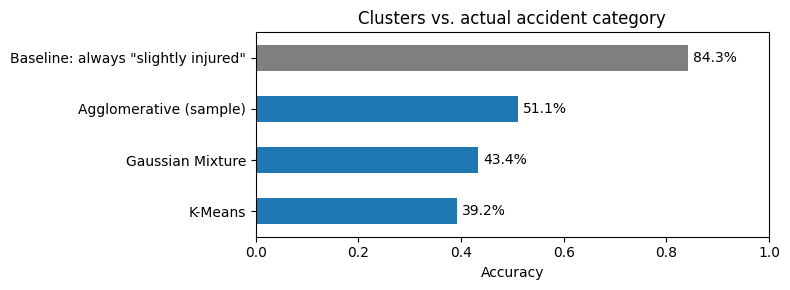

In [9]:
import matplotlib.pyplot as plt
ax = summary['Accuracy'].plot.barh(figsize=(8, 3), color=['tab:blue'] * 3 + ['tab:gray'])
ax.set_xlabel('Accuracy'); ax.set_xlim(0, 1); ax.set_title('Clusters vs. actual accident category')
for i, v in enumerate(summary['Accuracy']):
    ax.text(v + 0.01, i, f'{v:.1%}', va='center')
plt.tight_layout(); plt.show()

## 8. Conclusion <a class="anchor" id="8"></a>

[Table of Contents](#0.1)

* All three algorithms reach only about **39–51 % accuracy**. That is the same as clusters of the same size chosen at random,
  and far below the trivial baseline of always predicting "slightly injured" (84.3 %).
* The **Adjusted Rand Index is ≈ 0** for all three, so the clusters are practically unrelated to accident severity.
* Why: the algorithms group accidents by what is most different in the features (kind/type of accident, road users, and now also
  time of day, season and weekday), not by severity. Severity is heavily imbalanced (0.9 % killed, 14.8 % serious, 84.3 % slight),
  and in **every** feature group most accidents are "slightly injured". So no natural cluster can be "the killed accidents".
* Accuracy here is computed with a one-to-one mapping (each cluster = one category). If each cluster were instead labelled with its
  most frequent category, every cluster would become "slightly injured" and accuracy would be 84.3 % – which just equals the baseline.
* Clustering alone therefore cannot separate the accident categories in this form – see Part 2 for handling the imbalance.

# Part 2: Dealing with the class imbalance (focus: *killed*) <a class="anchor" id="part2"></a>

[Table of Contents](#0.1)

Killed is only 0.9 % of all accidents. Three things are done:
1. **Better metrics** – plain accuracy rewards ignoring *killed*. Use **balanced accuracy** (mean recall of the 3 classes, chance = 33 %)
   and, for *killed*: **recall** (share of fatal accidents found), **precision** and **lift** (precision ÷ 0.9 % base rate; lift 1 = no better than random).
2. **Balanced data** – undersample *seriously* and *slightly injured* to the number of *killed* accidents before clustering.
3. **More clusters than classes** – with k = 10 small "high-risk" clusters can form; each cluster gets the majority category (on the balanced data).

Clusters are fitted on a balanced **training** set and evaluated on a held-out **test** set with the **real** class distribution.

## 9. Part 1 results with imbalance-aware metrics <a class="anchor" id="9"></a>

[Table of Contents](#0.1)

In [10]:
from sklearn.metrics import balanced_accuracy_score, recall_score, precision_score

def scores(y_true, y_pred):
    prec = precision_score(y_true, y_pred, labels=[1], average=None, zero_division=0)[0]
    return {'Accuracy': accuracy_score(y_true, y_pred),
            'Balanced accuracy': balanced_accuracy_score(y_true, y_pred),
            'Killed recall': recall_score(y_true, y_pred, labels=[1], average=None)[0],
            'Killed precision': prec,
            'Killed lift': prec / (y_true == 1).mean(),
            'Share flagged as killed': (y_pred == 1).mean()}

part1 = {name: scores(y[idx] if 'sample' in name else y, p) for name, p in preds.items()}
part1['Baseline: always "slightly injured"'] = scores(y, np.full(len(y), 3))
pd.DataFrame(part1).T.round(3)

,Accuracy,Balanced accuracy,Killed recall,Killed precision,Killed lift,Share flagged as killed
K-Means,0.392,0.343,0.291,0.012,1.301,0.223
Gaussian Mixture,0.434,0.353,0.300,0.012,1.268,0.236
Agglomerative (sample),0.511,0.335,0.221,0.009,0.896,0.247
"Baseline: always ""slightly injured""",0.843,0.333,0.000,0.000,0.000,0.000


The 84 % baseline finds **0 %** of the fatal accidents and scores only 33 % balanced accuracy (chance level).
The Part 1 clusters are hardly better: balanced accuracy 34–35 %, and they find only 22–30 % of the fatal accidents (lift 0.9–1.3).

## 10. Balanced training sample + held-out test set <a class="anchor" id="10"></a>

[Table of Contents](#0.1)

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import pairwise_distances_argmin

train_idx, test_idx = train_test_split(np.arange(len(y)), test_size=0.3, stratify=y, random_state=42)
X_train, X_test, y_train, y_test = X[train_idx], X[test_idx], y[train_idx], y[test_idx]

# undersampling: all 'killed' of the training set + the same number of the other two classes
rng = np.random.default_rng(42)
n_killed = (y_train == 1).sum()
bal = np.concatenate([rng.choice(np.where(y_train == k)[0], n_killed, replace=False) for k in [1, 2, 3]])
X_bal, y_bal = X_train[bal], y_train[bal]
print('balanced training set:', pd.Series(y_bal).value_counts().sort_index().to_dict())
print('test set (real distribution):', pd.Series(y_test).value_counts().sort_index().to_dict())

balanced training set: {1: 1734, 2: 1734, 3: 1734}
test set (real distribution): {1: 743, 2: 12129, 3: 69031}


In [12]:
def cluster_and_map(algo, k, X_fit, y_fit):
    """Fit k clusters on X_fit, name each cluster with a category (using y_fit),
    return a function that predicts the category of new accidents."""
    if algo == 'Agglomerative' and len(X_fit) > 10_000:   # memory grows with n² -> random sample of 10,000
        s = np.random.default_rng(42).choice(len(X_fit), 10_000, replace=False)
        X_fit, y_fit = X_fit[s], y_fit[s]
    if algo == 'K-Means':
        m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_fit)
        c, assign = m.labels_, m.predict
    elif algo == 'Gaussian Mixture':
        m = GaussianMixture(n_components=k, random_state=42).fit(X_fit)
        c, assign = m.predict(X_fit), m.predict
    else:   # Agglomerative has no predict(): assign new points to the nearest cluster centre
        c = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_fit)
        centres = np.array([X_fit[c == i].mean(axis=0) for i in range(k)])
        assign = lambda Z: pairwise_distances_argmin(Z, centres)
    ct = pd.crosstab(c, y_fit).reindex(index=range(k), columns=[1, 2, 3], fill_value=0)
    if k == 3:   # one-to-one mapping as in Part 1
        r, cc = linear_sum_assignment(-ct.values)
        mapping = {ct.index[i]: ct.columns[j] for i, j in zip(r, cc)}
    else:        # each cluster gets its majority category
        mapping = ct.idxmax(axis=1).to_dict()
    return lambda Z: pd.Series(assign(Z)).map(mapping).values

part2 = {}
for k in [3, 10]:
    for algo in ['K-Means', 'Gaussian Mixture', 'Agglomerative']:
        part2[f'{algo} (k={k})'] = scores(y_test, cluster_and_map(algo, k, X_bal, y_bal)(X_test))

part2['Baseline: always "slightly injured"'] = scores(y_test, np.full(len(y_test), 3))
summary2 = pd.DataFrame(part2).T
summary2.round(3)

,Accuracy,Balanced accuracy,Killed recall,Killed precision,Killed lift,Share flagged as killed
K-Means (k=3),0.425,0.358,0.289,0.012,1.338,0.216
Gaussian Mixture (k=3),0.372,0.366,0.297,0.012,1.273,0.234
Agglomerative (k=3),0.278,0.369,0.291,0.012,1.320,0.220
K-Means (k=10),0.464,0.393,0.521,0.012,1.356,0.384
Gaussian Mixture (k=10),0.554,0.406,0.355,0.015,1.651,0.215
Agglomerative (k=10),0.436,0.393,0.445,0.011,1.242,0.359
"Baseline: always ""slightly injured""",0.843,0.333,0.000,0.000,0.000,0.000


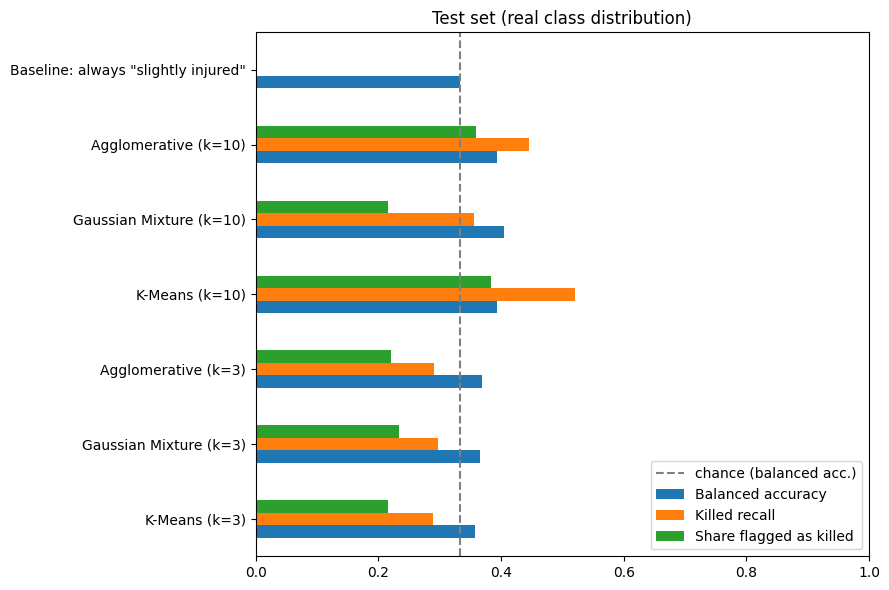

In [13]:
# high killed recall is only useful if not too many accidents are flagged -> show both
ax = summary2[['Balanced accuracy', 'Killed recall', 'Share flagged as killed']].plot.barh(figsize=(9, 6))
ax.axvline(1/3, color='gray', ls='--', label='chance (balanced acc.)')
ax.set_xlim(0, 1); ax.set_title('Test set (real class distribution)'); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

### Effect of the time features <a class="anchor" id="10.1"></a>

[Table of Contents](#0.1)

Same setup (K-Means, k = 10, balanced training set), once **with** and once **without** the 6 time columns.
Hour and weekday do carry information on severity (see section 2), so one might expect better clusters:

In [14]:
compare = {}
for name, cols in [('without time features', slice(0, -n_time)), ('with time features', slice(None))]:
    m = KMeans(n_clusters=10, n_init=10, random_state=42).fit(X_bal[:, cols])
    mapping = pd.crosstab(m.labels_, y_bal).idxmax(axis=1).to_dict()
    compare[name] = scores(y_test, pd.Series(m.predict(X_test[:, cols])).map(mapping).values)
pd.DataFrame(compare).T.round(3)

,Accuracy,Balanced accuracy,Killed recall,Killed precision,Killed lift,Share flagged as killed
without time features,0.546,0.465,0.553,0.022,2.417,0.229
with time features,0.464,0.393,0.521,0.012,1.356,0.384


## 11. Conclusion on the imbalance <a class="anchor" id="11"></a>

[Table of Contents](#0.1)

* **Accuracy is the wrong metric here.** The 84 % baseline finds no fatal accident. Use balanced accuracy and killed recall/precision.
* **Balancing + k = 3 clusters:** balanced accuracy 36–37 %, about 29 % of fatal accidents found, lift ≈ 1.3 – only slightly better than random.
* **Balancing + k = 10 clusters** is somewhat better: balanced accuracy 39–41 %. Gaussian Mixture gives the highest lift (1.65);
  K-Means finds the most fatal accidents (52 %) but flags 38 % of all accidents.
* **The time features make the clusters worse, not better** (K-Means k = 10: balanced accuracy 0.47 → 0.39, lift 2.4 → 1.4).
  The 6 time columns account for almost half of the total variance, so the clusters now mainly split accidents by
  time of day, season and weekday. The part of the time signal that matters for severity – night hours with low traffic – covers
  only ~3 % of accidents, too few to form a cluster of its own. Month adds variance with almost no link to severity.
  Repeating with 2 other random splits gave the same picture (with time: balanced accuracy 0.38–0.40, lift 1.3–1.6).
* Even the best variants only narrow fatal accidents down to a group with a somewhat higher risk (killed precision 1–2 %
  vs. a 0.9 % base rate); they cannot separate them.
* Oversampling with SMOTE instead of undersampling is tested in Part 4.
* Possible next steps: give the time features less weight or use simple flags (night, weekend) instead of month/hour
  curves, and add location (e.g. rural vs. urban from coordinates or municipality).

# Part 3: DBSCAN with grid search (exactly 3 clusters) <a class="anchor" id="part3"></a>

[Table of Contents](#0.1)

DBSCAN has no "number of clusters" parameter. It finds dense regions controlled by `eps` (neighbourhood radius) and
`min_samples` (points needed in that radius). Points that belong to no dense region are labelled **noise** (-1).

Setup (same data as Part 2, so the results are comparable):
* **Grid:** `eps` × `min_samples`, fitted on the balanced training set. Only combinations that give **exactly 3 clusters** are kept.
* **Noise:** to keep exactly three groups, each noise point is assigned to the cluster of its **nearest core point**.
  New (test) accidents are assigned the same way, because DBSCAN has no `predict()`.
* **Best parameters:** highest balanced accuracy on the *training* set (clusters mapped one-to-one to categories as in Part 1).
  The test set is only used for the final evaluation.
* **Grid range:** `eps` 0.5–2.5 (step 0.1) and `min_samples` 5–200 (step 5). A first coarse scan showed that exactly
  3 clusters only occur in this range.

In [15]:
from sklearn.cluster import DBSCAN

def dbscan_3(eps, min_samples, X_fit):
    """Fit DBSCAN; return (n_clusters, noise share, function that assigns any data to the nearest core point's cluster)."""
    db = DBSCAN(eps=eps, min_samples=min_samples).fit(X_fit)
    n_clusters = len(set(db.labels_)) - (-1 in db.labels_)
    noise = (db.labels_ == -1).mean()
    cores, core_labels = X_fit[db.core_sample_indices_], db.labels_[db.core_sample_indices_]
    assign = lambda Z: core_labels[pairwise_distances_argmin(Z, cores)] if len(cores) else None
    return n_clusters, noise, assign

def map_3_clusters(y_true, clusters):
    ct = pd.crosstab(clusters, y_true).reindex(index=range(3), columns=[1, 2, 3], fill_value=0)
    r, c = linear_sum_assignment(-ct.values)
    return {ct.index[i]: ct.columns[j] for i, j in zip(r, c)}

def dbscan_grid_search(X_fit, y_fit):
    """Try all eps / min_samples combinations; score the ones with exactly 3 clusters on the training data."""
    grid = []
    for eps in np.round(np.arange(0.5, 2.51, 0.1), 1):
        for min_samples in range(5, 201, 5):
            n_clusters, noise, assign = dbscan_3(eps, min_samples, X_fit)
            row = {'eps': eps, 'min_samples': min_samples, 'n_clusters': n_clusters, 'noise share': noise}
            if n_clusters == 3:
                c = assign(X_fit)
                row['balanced acc. (train)'] = balanced_accuracy_score(y_fit, pd.Series(c).map(map_3_clusters(y_fit, c)))
            grid.append(row)
    return pd.DataFrame(grid)

def dbscan_best_predictor(grid, X_fit, y_fit):
    """Refit DBSCAN with the best 3-cluster parameters; return (best row, function that predicts categories)."""
    best = grid[grid.n_clusters == 3].sort_values('balanced acc. (train)', ascending=False).iloc[0]
    _, _, assign = dbscan_3(best.eps, int(best.min_samples), X_fit)
    mapping = map_3_clusters(y_fit, assign(X_fit))
    return best, lambda Z: pd.Series(assign(Z)).map(mapping).values

In [16]:
grid = dbscan_grid_search(X_bal, y_bal)

print(f'{len(grid)} combinations tested, {(grid.n_clusters == 3).sum()} give exactly 3 clusters')
grid[grid.n_clusters == 3].sort_values('balanced acc. (train)', ascending=False).round(3).head(10)

840 combinations tested, 25 give exactly 3 clusters


,eps,min_samples,n_clusters,noise share,balanced acc. (train)
530,1.8,55,3,0.514,0.389
572,1.9,65,3,0.426,0.389
574,1.9,75,3,0.465,0.387
445,1.6,30,3,0.592,0.387
531,1.8,60,3,0.534,0.387
573,1.9,70,3,0.441,0.386
576,1.9,85,3,0.502,0.385
575,1.9,80,3,0.484,0.385
488,1.7,45,3,0.584,0.384
532,1.8,65,3,0.560,0.382


In [17]:
# number of clusters over the grid (selected min_samples values)
grid[grid.min_samples.isin([5, 10, 20, 30, 50, 75, 100, 150, 200])] \
    .pivot(index='min_samples', columns='eps', values='n_clusters')

eps,0.5,0.6,0.7,0.8,0.9,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,1.9,2.0,2.1,2.2,2.3,2.4,2.5
min_samples,,,,,,,,,,,,,,,,,,,,,
5,3,56,56,77,65,60,73,70,75,82,23,9,4,2,1,1,1,1,1,1,1
10,0,1,1,5,9,16,20,19,24,31,12,5,1,3,1,1,1,1,1,1,1
20,0,0,0,0,0,1,4,8,10,8,8,6,2,1,1,1,1,1,1,1,1
30,0,0,0,0,0,0,1,1,3,4,5,3,6,3,1,1,1,1,1,1,1
50,0,0,0,0,0,0,0,0,0,2,1,4,4,4,3,1,1,1,1,1,1
75,0,0,0,0,0,0,0,0,0,0,2,1,2,4,3,1,1,1,1,1,1
100,0,0,0,0,0,0,0,0,0,0,0,0,1,2,3,1,1,1,1,1,1
150,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,3,1,1,1,1,1
200,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,2,1,1,1,1


Small `eps` → dozens to hundreds of tiny clusters; `eps` ≥ 2.1 → (almost) everything merges into 1 cluster.
Exactly 3 clusters only appear in a narrow band (mostly `eps` 1.6–2.0), where a large share of points is noise.

In [18]:
best, predict_db = dbscan_best_predictor(grid, X_bal, y_bal)
print(f"Best parameters: eps = {best.eps}, min_samples = {int(best.min_samples)}, noise share (train) = {best['noise share']:.1%}")

part2['DBSCAN (3 clusters, grid search)'] = scores(y_test, predict_db(X_test))
summary3 = pd.DataFrame(part2).T
summary3.round(3)

Best parameters: eps = 1.8, min_samples = 55, noise share (train) = 51.4%


,Accuracy,Balanced accuracy,Killed recall,Killed precision,Killed lift,Share flagged as killed
K-Means (k=3),0.425,0.358,0.289,0.012,1.338,0.216
Gaussian Mixture (k=3),0.372,0.366,0.297,0.012,1.273,0.234
Agglomerative (k=3),0.278,0.369,0.291,0.012,1.320,0.220
K-Means (k=10),0.464,0.393,0.521,0.012,1.356,0.384
Gaussian Mixture (k=10),0.554,0.406,0.355,0.015,1.651,0.215
Agglomerative (k=10),0.436,0.393,0.445,0.011,1.242,0.359
"Baseline: always ""slightly injured""",0.843,0.333,0.000,0.000,0.000,0.000
"DBSCAN (3 clusters, grid search)",0.422,0.380,0.320,0.010,1.102,0.291


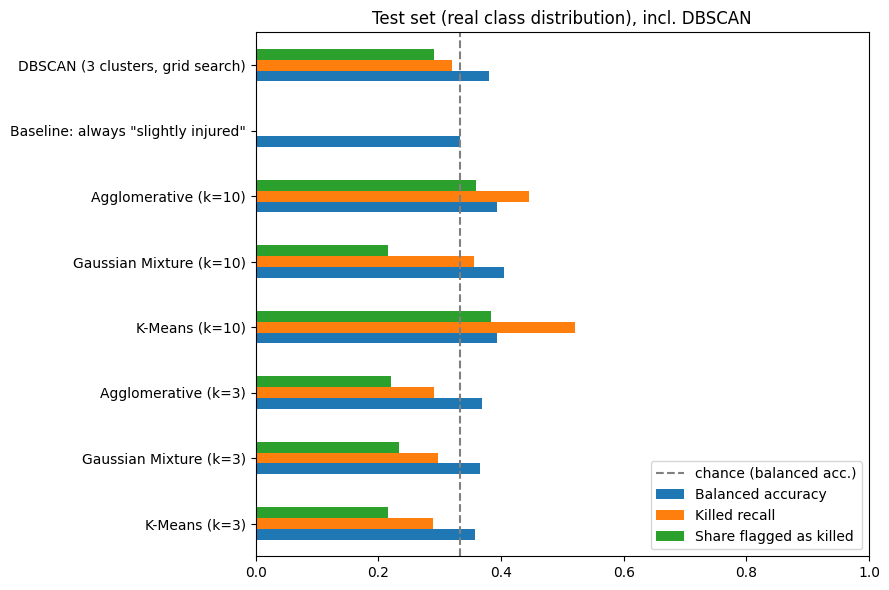

In [19]:
ax = summary3[['Balanced accuracy', 'Killed recall', 'Share flagged as killed']].plot.barh(figsize=(9, 6))
ax.axvline(1/3, color='gray', ls='--', label='chance (balanced acc.)')
ax.set_xlim(0, 1); ax.set_title('Test set (real class distribution), incl. DBSCAN'); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

## 12. Conclusion on DBSCAN <a class="anchor" id="12"></a>

[Table of Contents](#0.1)

* DBSCAN is **not a good fit** for this data. Small `eps` gives dozens to hundreds of tiny clusters, large `eps` merges
  everything into one cluster. Only 25 of 840 parameter combinations give exactly 3 clusters, and all of them label
  **a large share of accidents as noise** (about half for the best combination).
* Best parameters (train): `eps` = 1.8, `min_samples` = 55. On the test set: balanced accuracy 0.38, only 32 % of fatal
  accidents found, lift ≈ 1.1 – about random, and not better than K-Means / GMM / Agglomerative.
* **Not stable:** repeating the grid search with 4 other random splits picked very different parameters
  (`eps` 0.6–1.9, `min_samples` 10–80, noise 48–99 %), with test balanced accuracy 0.37–0.38 each time.
* With the time features DBSCAN got worse than before (balanced accuracy 0.43 → 0.38) for the same reason as the other methods.
* Note: choosing the parameters with the labels (balanced accuracy on the training set) is a form of supervision.
  Without labels, DBSCAN would give even less reason to pick these settings.

# Part 4: SMOTE oversampling instead of undersampling <a class="anchor" id="part4"></a>

[Table of Contents](#0.1)

Undersampling (Parts 2–3) throws away ~97 % of the training accidents. **SMOTE** does the opposite: it keeps all real accidents and
creates **synthetic** *killed* and *seriously injured* accidents until every class is as large as *slightly injured*.
A synthetic accident is placed between a real accident and one of its nearest neighbours of the same class.

* **SMOTENC** (SMOTE for mixed data) is used: plain SMOTE would interpolate the one-hot columns and create impossible values
  (e.g. "40 % leaving the road to the right, 60 % to the left"). SMOTENC interpolates only the time columns and gives the
  categorical columns the most common value among the neighbours. The result is then one-hot encoded as before.
* SMOTE is applied to the **training set only**. The test set is the same untouched one as in Parts 2–3 (real class distribution).
* Agglomerative clustering and DBSCAN cannot handle ~480,000 rows (memory/time), so they use a random sample
  of the SMOTE data (10,000 rows for Agglomerative as in Part 1; 5,202 rows for DBSCAN, the same size as the undersampled set).
* Requires `pip install imbalanced-learn`. **Runtime:** this part takes ~12 minutes (SMOTENC ~5 min, Gaussian Mixture k = 10 ~5 min).

In [20]:
from imblearn.over_sampling import SMOTENC

n_cat = len(cat_cols + bin_cols)   # the first columns of `raw` are categorical
smote = SMOTENC(categorical_features=list(range(n_cat)), random_state=42)
raw_smote, y_smote = smote.fit_resample(raw.iloc[train_idx], y_train)
X_smote = encode(raw_smote).reindex(columns=features.columns, fill_value=0).values

print('training set before SMOTE:', pd.Series(y_train).value_counts().sort_index().to_dict())
print('training set after SMOTE: ', pd.Series(y_smote).value_counts().sort_index().to_dict())
print(f"synthetic share of 'killed' after SMOTE: {1 - (y_train == 1).sum() / (y_smote == 1).sum():.1%}")

training set before SMOTE: {1: 1734, 2: 28301, 3: 161069}
training set after SMOTE:  {1: 161069, 2: 161069, 3: 161069}
synthetic share of 'killed' after SMOTE: 98.9%


## 13. K-Means, Gaussian Mixture, Agglomerative and DBSCAN on the SMOTE data <a class="anchor" id="13"></a>

[Table of Contents](#0.1)

In [21]:
part4 = {}
for k in [3, 10]:
    for algo in ['K-Means', 'Gaussian Mixture', 'Agglomerative']:
        part4[f'{algo} (k={k})'] = scores(y_test, cluster_and_map(algo, k, X_smote, y_smote)(X_test))

# DBSCAN: same grid search as in Part 3, on a random sample of the SMOTE data
s = np.random.default_rng(42).choice(len(X_smote), len(X_bal), replace=False)
grid_smote = dbscan_grid_search(X_smote[s], y_smote[s])
best_smote, predict_db_smote = dbscan_best_predictor(grid_smote, X_smote[s], y_smote[s])
print(f"DBSCAN best parameters: eps = {best_smote.eps}, min_samples = {int(best_smote.min_samples)}, "
      f"noise share = {best_smote['noise share']:.1%}")
part4['DBSCAN (3 clusters, grid search)'] = scores(y_test, predict_db_smote(X_test))
pd.DataFrame(part4).T.round(3)

DBSCAN best parameters: eps = 1.3, min_samples = 40, noise share = 92.6%


,Accuracy,Balanced accuracy,Killed recall,Killed precision,Killed lift,Share flagged as killed
K-Means (k=3),0.429,0.357,0.277,0.012,1.331,0.208
Gaussian Mixture (k=3),0.205,0.358,0.297,0.012,1.273,0.234
Agglomerative (k=3),0.294,0.370,0.283,0.012,1.367,0.207
K-Means (k=10),0.617,0.408,0.376,0.017,1.900,0.198
Gaussian Mixture (k=10),0.627,0.382,0.167,0.012,1.300,0.128
Agglomerative (k=10),0.428,0.405,0.598,0.013,1.425,0.419
"DBSCAN (3 clusters, grid search)",0.619,0.398,0.275,0.017,1.902,0.144


## 14. Undersampling vs. SMOTE (same test set) <a class="anchor" id="14"></a>

[Table of Contents](#0.1)

In [22]:
under = summary3.drop('Baseline: always "slightly injured"')
smote_res = pd.DataFrame(part4).T
cols = ['Balanced accuracy', 'Killed recall', 'Killed lift', 'Share flagged as killed']
comparison = pd.concat({'Undersampling': under[cols], 'SMOTE': smote_res[cols]}, axis=1).swaplevel(axis=1)[cols]
comparison.round(3)

Balanced accuracy        Killed recall  \
                                     Undersampling  SMOTE Undersampling   
K-Means (k=3)                                0.358  0.357         0.289   
Gaussian Mixture (k=3)                       0.366  0.358         0.297   
Agglomerative (k=3)                          0.369  0.370         0.291   
K-Means (k=10)                               0.393  0.408         0.521   
Gaussian Mixture (k=10)                      0.406  0.382         0.355   
Agglomerative (k=10)                         0.393  0.405         0.445   
DBSCAN (3 clusters, grid search)             0.380  0.398         0.320   

                                          Killed lift         \
                                  SMOTE Undersampling  SMOTE   
K-Means (k=3)                     0.277         1.338  1.331   
Gaussian Mixture (k=3)            0.297         1.273  1.273   
Agglomerative (k=3)               0.283         1.320  1.367   
K-Means (k=10)                    0.376         1.356  1.900   
Gaussian Mixture (k=10)           0.167         1.651  1.300   
Agglomerative (k=10)              0.598         1.242  1.425   
DBSCAN (3 clusters, grid search)  0.275         1.102  1.902   

                                 Share flagged as killed         
                                           Undersampling  SMOTE  
K-Means (k=3)                                      0.216  0.208  
Gaussian Mixture (k=3)                             0.234  0.234  
Agglomerative (k=3)                                0.220  0.207  
K-Means (k=10)                                     0.384  0.198  
Gaussian Mixture (k=10)                            0.215  0.128  
Agglomerative (k=10)                               0.359  0.419  
DBSCAN (3 clusters, grid search)                   0.291  0.144

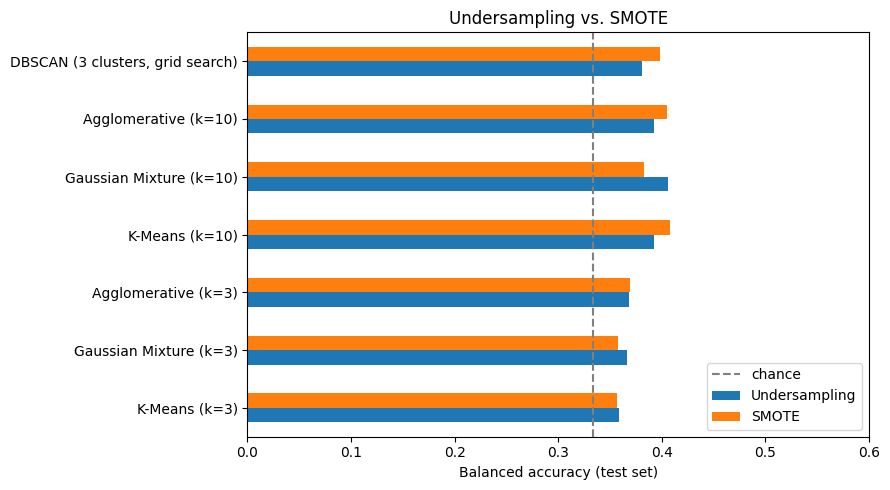

In [23]:
ax = comparison['Balanced accuracy'].plot.barh(figsize=(9, 5))
ax.axvline(1/3, color='gray', ls='--', label='chance')
ax.set_xlim(0, 0.6); ax.set_xlabel('Balanced accuracy (test set)'); ax.set_title('Undersampling vs. SMOTE')
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

## 15. Conclusion on SMOTE <a class="anchor" id="15"></a>

[Table of Contents](#0.1)

* SMOTE balances the training set to 161,069 accidents per class. **98.9 % of the *killed* accidents are synthetic** – they are all
  built from the same 1,734 real fatal accidents. SMOTE adds no new information about fatal accidents, only more points between existing ones.
* **Results on this split are mixed:**
  * k = 3: practically identical to undersampling (balanced accuracy 0.36–0.37, lift ≈ 1.3).
  * K-Means k = 10 (0.39 → 0.41, lift 1.4 → 1.9), Agglomerative k = 10 (0.39 → 0.41) and DBSCAN (0.38 → 0.40, lift 1.1 → 1.9) are slightly better,
  * Gaussian Mixture k = 10 is worse (0.41 → 0.38, lift 1.65 → 1.3).
* **Repeated with 3 other random splits, the differences are within the normal run-to-run variation:**
  average balanced accuracy k = 3: 0.36 (SMOTE) vs. 0.36 (undersampling); k = 10: 0.41 vs. 0.40; DBSCAN: 0.38 vs. 0.37.
  Lift for k = 10 was slightly higher on average with SMOTE (1.7 vs. 1.5), but individual runs go both ways.
  DBSCAN's best parameters again changed from split to split (`eps` 1.5–2.0, `min_samples` 75–165, noise 50–92 %).
* Why so little difference: clustering does not learn from the labels. Balancing only changes how much weight each class gets
  when the clusters are formed – undersampling and SMOTE both give the classes equal weight, so the clusters end up similar.
* **Cost:** ~480,000 instead of ~5,200 training rows, ~12 extra minutes of runtime, and Agglomerative / DBSCAN still need a sample.
* **Overall:** SMOTE does not solve the problem. The limit is the weak link between these features and accident severity,
  not the number of fatal accidents. For clustering, simple undersampling is as good and much faster.